In [27]:
import pandas as pd
import matplotlib.pyplot as plt

In [28]:
f = "/Users/claracheng/Downloads/209a Final Project/raw/IntGenbyFuel2026.xlsx"
jan = pd.read_excel(f, sheet_name="Jan")
print(jan.shape)
jan.head(12)

(310, 100)


,Date,Fuel,Settlement Type,Total,0:15,0:30,0:45,1:00,1:15,1:30,...,21:45,22:00,22:15,22:30,22:45,23:00,23:15,23:30,23:45,0:00
0,2026-01-01,Biomass,FINAL,1541.707187,16.145577,16.151536,16.157284,16.140920,16.163235,16.155516,...,16.016234,16.028450,16.032505,16.020557,16.039506,16.022077,16.026245,16.037347,16.044356,16.015325
1,2026-01-01,Coal,FINAL,129637.336335,1373.394155,1311.644001,1292.717576,1318.350130,1336.662201,1328.747982,...,1140.027430,1136.380136,1145.251208,1135.882407,1136.871945,1133.475566,1133.674890,1132.411637,1132.650103,1135.446758
2,2026-01-01,Gas,FINAL,42024.071532,482.317341,430.766043,423.920493,436.268292,449.653681,454.751215,...,353.848954,359.264096,388.325746,403.809155,402.854032,394.797440,378.934592,376.314039,372.397416,367.108907
3,2026-01-01,Gas-CC,FINAL,327488.224318,3981.376026,4073.287351,4080.744865,4129.954980,4168.250222,4226.117816,...,2594.298165,2535.702348,2384.698400,2208.924618,2178.452822,2160.836303,2143.453753,2098.172003,2134.804488,2170.914950
4,2026-01-01,Hydro,FINAL,829.042719,0.011149,0.000000,0.000000,0.000000,0.000000,0.000000,...,5.019165,5.023297,5.035449,5.005417,5.016625,4.007418,0.000000,0.000000,0.000000,0.000000
5,2026-01-01,Nuclear,FINAL,122397.513720,1274.687635,1274.749265,1274.770497,1274.671345,1274.582687,1274.679173,...,1275.669220,1275.508477,1275.244880,1274.857838,1275.279587,1275.204009,1275.488538,1275.518796,1274.910368,1274.302011
6,2026-01-01,Other,FINAL,15962.112176,13.977809,2.313308,5.206845,10.419043,59.760599,35.670492,...,132.070222,87.287199,151.146383,154.686991,123.029277,92.582086,31.399659,11.633543,40.277583,21.662800
7,2026-01-01,Solar,FINAL,137551.650248,0.036736,0.000090,0.000084,0.012360,0.000982,0.000072,...,0.001035,0.001059,0.000078,0.001954,0.001021,0.001983,0.000102,0.000862,0.000096,0.000078
8,2026-01-01,WSL,FINAL,-24395.132249,-720.808063,-804.413580,-793.739795,-867.280907,-899.556980,-794.338889,...,-153.063533,-122.160730,-191.092031,-134.550488,-139.287289,-164.097280,-174.859964,-222.826075,-203.237660,-203.369258
9,2026-01-01,Wind,FINAL,376055.910945,5135.109260,5214.495419,5251.466680,5225.255636,5153.504063,5041.546580,...,6361.516554,6382.808066,6366.857032,6403.802721,6358.782967,6343.885667,6342.606166,6346.455779,6164.522429,6051.869033


In [29]:
months = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
frames = [pd.read_excel(f, sheet_name=m) for m in months]
wide = pd.concat([d for d in frames if len(d) > 0], ignore_index=True)
print(wide.shape)

(3040, 100)


In [30]:
interval_cols = [c for c in wide.columns if ":" in str(c)]

print(wide["Fuel"].value_counts())
print("Duplicates:", wide.duplicated(["Date", "Fuel"]).sum())
print("Missing values:", wide[interval_cols].isna().sum().sum())
diff = (wide["Total"] - wide[interval_cols].sum(axis=1)).abs()
print("Biggest mismatch:", diff.max())
print(wide.loc[(wide[interval_cols] < 0).any(axis=1), "Fuel"].unique())
print(wide["Settlement Type"].value_counts())

Fuel
Biomass    304
Coal       304
Gas        304
Gas-CC     304
Hydro      304
Nuclear    304
Other      304
Solar      304
WSL        304
Wind       304
Name: count, dtype: int64
Duplicates: 0
Missing values: 40
Biggest mismatch: 1.000124029815197e-06
<StringArray>
['WSL']
Length: 1, dtype: str
Settlement Type
FINAL      2430
INITIAL     610
Name: count, dtype: int64


In [31]:
pieces = []
for col in interval_cols:
    piece = wide[["Date", "Fuel", "Settlement Type"]].copy()
    piece["interval"] = col
    piece["mwh"] = wide[col]
    pieces.append(piece)

long = pd.concat(pieces, ignore_index=True).dropna(subset=["mwh"])

parts = long["interval"].str.split(":", expand=True).astype(int)
offset = pd.to_timedelta(parts[0], unit="h") + pd.to_timedelta(parts[1], unit="m")
offset = offset.where(offset > pd.Timedelta(0), pd.Timedelta(hours=24))
long["start"] = pd.to_datetime(long["Date"]) + offset - pd.Timedelta(minutes=15)
long["hour"] = long["start"].dt.floor("h")

long = long.sort_values(["start", "Fuel"])
long.head(12)

hourly = long.pivot_table(
    index="hour",
    columns="Fuel",
    values="mwh",
    aggfunc="sum"
)

print(hourly.shape)
hourly.head()

(7295, 10)


Fuel,Biomass,Coal,Gas,Gas-CC,Hydro,Nuclear,Other,Solar,WSL,Wind
hour,,,,,,,,,,
2026-01-01 00:00:00,64.595317,5296.105862,1773.272169,16265.363222,0.011149,5098.878742,31.917005,0.049270,-3186.242345,20826.326995
2026-01-01 01:00:00,64.630152,5278.099361,1824.188323,16909.558679,0.000000,5098.377738,177.836942,0.002758,-2988.221401,19940.669313
2026-01-01 02:00:00,64.591795,5202.567441,1839.589825,17160.000097,0.000000,5086.165227,146.642672,0.000294,-1349.155869,18238.561056
2026-01-01 03:00:00,64.566604,5648.527718,1886.775532,18011.299363,2.343789,5098.591204,90.598109,0.000330,-747.763468,16543.050501
2026-01-01 04:00:00,64.511293,6026.682161,1991.186638,18462.705458,76.064415,5098.765813,97.536338,0.059194,-448.568568,15741.322151


In [32]:
EF = {
    "Coal": 1021,
    "Gas-CC": 398,
    "Gas": 557,
    "Biomass": 0,
    "Hydro": 0,
    "Nuclear": 0,
    "Other": 0,
    "Solar": 0,
    "Wind": 0,
}

gen_cols = ["Coal", "Gas-CC", "Gas", "Biomass", "Hydro", "Nuclear", "Other", "Solar", "Wind"]

hourly["total_gen"] = 0
for fuel in gen_cols:
    hourly["total_gen"] = hourly["total_gen"] + hourly[fuel]

hourly["co2_kg"] = 0
for fuel in gen_cols:
    hourly["co2_kg"] = hourly["co2_kg"] + hourly[fuel] * EF[fuel]

hourly["carbon_intensity"] = hourly["co2_kg"] / hourly["total_gen"]

print(hourly["carbon_intensity"].describe())

hourly.to_csv("/Users/claracheng/Downloads/209a Final Project/clean/ercot_hourly_clean_2026.csv")

count    7295.000000
mean      291.599947
std        81.893447
min        73.187222
25%       232.023980
50%       291.262040
75%       356.967192
max       500.706600
Name: carbon_intensity, dtype: float64


0 331.2
1 327.8
2 327.2
3 330.0
4 334.4
5 340.2
6 340.8
7 330.0
8 278.0
9 231.8
10 216.7
11 212.1
12 213.9
13 219.2
14 224.8
15 231.9
16 244.5
17 270.0
18 301.6
19 327.8
20 339.2
21 342.8
22 343.8
23 338.7


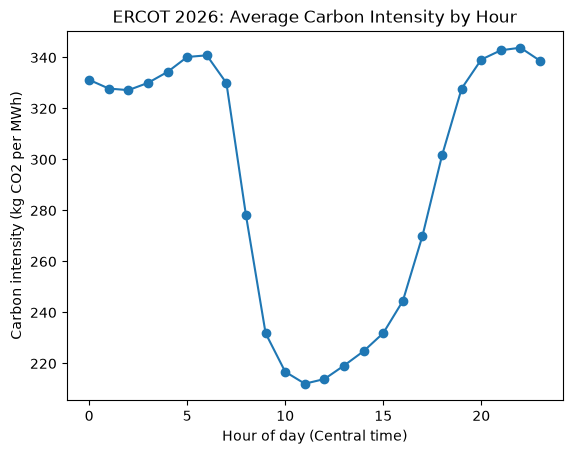

In [33]:
hourly["hour_of_day"] = hourly.index.hour
hours = []
averages = []

for h in range(24):
    rows_for_this_hour = hourly[hourly["hour_of_day"] == h]
    avg = rows_for_this_hour["carbon_intensity"].mean()
    hours.append(h)
    averages.append(avg)

for i in range(24):
    print(hours[i], round(averages[i], 1))

plt.plot(hours, averages, marker="o")
plt.xlabel("Hour of day (Central time)")
plt.ylabel("Carbon intensity (kg CO2 per MWh)")
plt.title("ERCOT 2026: Average Carbon Intensity by Hour")
plt.show()

1 306.1
2 263.9
3 224.2
4 271.7
5 277.0
6 289.9
7 319.5
8 318.8
9 334.4
10 308.5


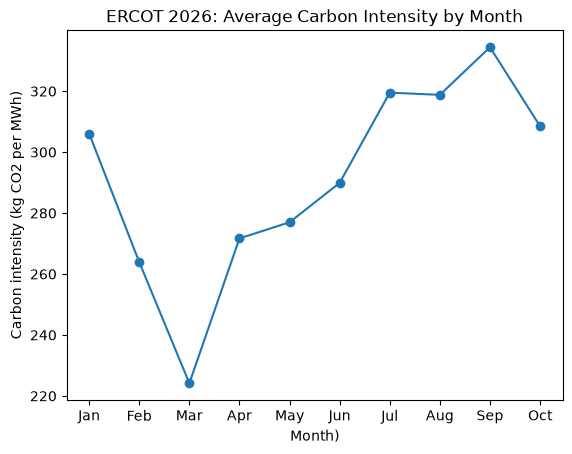

<Figure size 640x480 with 0 Axes>

In [ ]:
hourly["month"] = hourly.index.month

month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct"]
month_numbers = []
month_averages = []

for m in range(1, 11):
    rows_for_this_month = hourly[hourly["month"] == m]
    avg = rows_for_this_month["carbon_intensity"].mean()
    month_numbers.append(m)
    month_averages.append(avg)

for i in range(len(month_numbers)):
    print(month_numbers[i], round(month_averages[i], 1))

plt.plot(month_names, month_averages, marker="o")
plt.xlabel("Month")
plt.ylabel("Carbon intensity (kg CO2 per MWh)")
plt.title("ERCOT 2026: Average Carbon Intensity by Month")
plt.show()
plt.savefig("/Users/claracheng/Downloads/209a Final Project/clean/fig2_carbon_intensity_by_month.png", bbox_inches="tight")

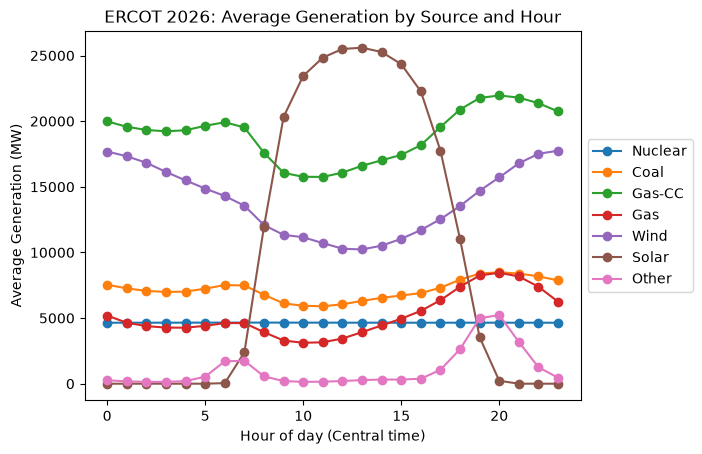

<Figure size 640x480 with 0 Axes>

In [66]:
sources = ["Nuclear", "Coal", "Gas-CC", "Gas", "Wind", "Solar", "Other"]

for source in sources:
    sources_averages = []

    for h in range(24):
        rows_for_this_hour = hourly[hourly["hour_of_day"] == h]
        avg = rows_for_this_hour[source].mean()
        sources_averages.append(avg)

    plt.plot(hours, sources_averages, marker="o", label=source)

plt.xlabel("Hour of day (Central time)")
plt.ylabel("Average Generation (MW)")
plt.title("ERCOT 2026: Average Generation by Source and Hour")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.show()


plt.savefig("/Users/claracheng/Downloads/209a Final Project/clean/fig3_generation_by_source_and_hour.png", bbox_inches="tight")

304
0 3
1 1
2 0
3 0
4 0
5 0
6 0
7 0
8 1
9 16
10 76
11 71
12 41
13 33
14 29
15 22
16 6
17 3
18 0
19 0
20 0
21 0
22 1
23 1


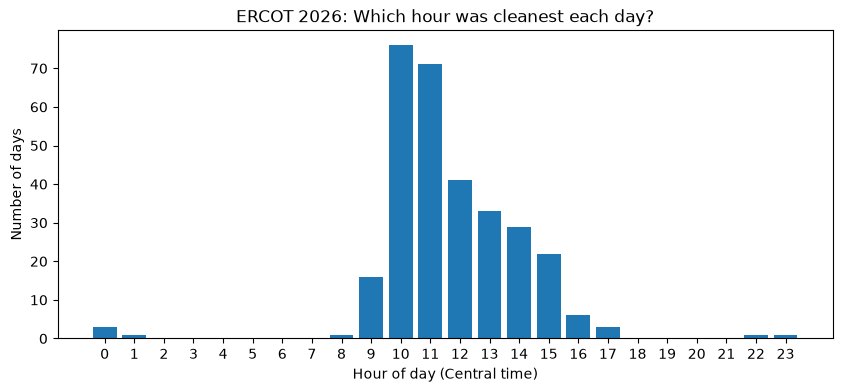

<Figure size 640x480 with 0 Axes>

In [ ]:
hourly["date"] = hourly.index.date
all_days = hourly["date"].unique()

cleanest_hours = []

for d in all_days:
    rows_for_this_day = hourly[hourly["date"] == d]
    cleanest_time = rows_for_this_day["carbon_intensity"].idxmin()
    cleanest_hours.append(cleanest_time.hour)

print(len(cleanest_hours))

counts = []
for h in range(24):
    counts.append(0)

for h in cleanest_hours:
    counts[h] = counts[h] + 1

for h in range(24):
    print(h, counts[h])

plt.figure(figsize=(10, 4))
plt.bar(range(24), counts)
plt.xlabel("Hour of day (Central time)")
plt.ylabel("Number of days")
plt.title("ERCOT 2026: Which hour was cleanest each day?")
plt.xticks(range(24))
plt.show()


Random time: 291.6
Always 10 a.m.: 216.7
Always best: 201.0


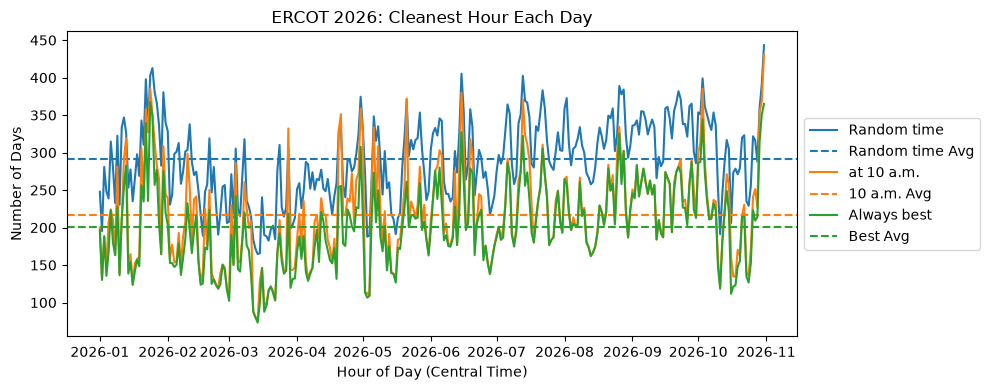

<Figure size 640x480 with 0 Axes>

In [65]:
daily_average = []
daily_at_10am = []
daily_best = []

for d in all_days:
    rows_for_this_day = hourly[hourly["date"] == d]

    avg = rows_for_this_day["carbon_intensity"].mean()
    best = rows_for_this_day["carbon_intensity"].min()

    row_at_10 = rows_for_this_day[rows_for_this_day["hour_of_day"] == 10]
    at_10 = row_at_10["carbon_intensity"].mean()

    daily_average.append(avg)
    daily_at_10am.append(at_10)
    daily_best.append(best)

# Yearly average
total_average = 0
for i in range(len(all_days)):
    total_average = total_average + daily_average[i]
mean_average = total_average / len(all_days)

total_at_10am = 0
for i in range(len(all_days)):
    total_at_10am = total_at_10am + daily_at_10am[i]
mean_at_10am = total_at_10am / len(all_days)

total_best = 0
for i in range(len(all_days)):
    total_best = total_best + daily_best[i]
mean_best = total_best / len(all_days)

print("Random time:", round(mean_average, 1))
print("Always 10 a.m.:", round(mean_at_10am, 1))
print("Always best:", round(mean_best, 1))


plt.figure(figsize=(10, 4))

plt.plot(all_days, daily_average, color="tab:blue", label="Random time")
plt.axhline(mean_average, color="tab:blue", linestyle="--", label="Random time Avg")
plt.plot(all_days, daily_at_10am, color="tab:orange", label="at 10 a.m.")
plt.axhline(mean_at_10am, color="tab:orange", linestyle="--", label="10 a.m. Avg")
plt.plot(all_days, daily_best, color="tab:green", label="Always best")
plt.axhline(mean_best, color="tab:green", linestyle="--", label="Best Avg")

plt.xlabel("Hour of Day (Central Time)")
plt.ylabel("Number of Days")
plt.title("ERCOT 2026: Cleanest Hour Each Day")
plt.legend(loc="center left", bbox_to_anchor=(1, 0.5))
plt.tight_layout()
plt.show()

plt.savefig("/Users/claracheng/Downloads/209a Final Project/clean/fig4_cleanest_hour_each_day.png", bbox_inches="tight")